# CbyD · comparative analysis

CbyD compared with the route-level (USPTO-190, PaRoutes) and one-step (USPTO-Full, Pistachio) datasets.
All tables come precomputed from `data/data_analysis/` (see `README.md`); the code behind each section is in `analysis/utils/`.
Figures are saved to `data/data_analysis/figures/` (SI figures in `figures/SI/`).

| § | section | module | figures |
|---|---|---|---|
| 1 | Dataset overview | `overview.py` | `dataset_overview`, SI `target_complexity_metrics`, `top15_heterocycles` |
| 2 | Reaction complexity | `reaction_complexity.py` | `reaction_complexity`, SI `cc_cx_bonds`, `product_complexity` |
| 3 | Route analysis | `route_analysis.py` | `convergency_dot` |
| 4 | Starting materials | `starting_materials.py` | SI `starting_materials_not_buyable`, `traced_stereo_provtree_*` |
| 5 | Complexity evolution & key steps | `complexity_evolution.py`, `keystep_figure.py` | `sascore_keysteps`, SI `complexity_evolution_keysteps`, `keystep_sascore_tree_*` |
| 6 | Source data: Table 2 + the numbers behind every figure | `source_data.py` | SI `supplementary_tables.docx` |

In [1]:
%load_ext autoreload
%autoreload 2
import os, sys, warnings
warnings.filterwarnings("ignore")
sys.path.insert(0, os.path.abspath(".."))          # analysis/ on the path
from IPython.display import display, SVG
from utils import figure_template as ft, complexity as cx
from utils import overview as ov, reaction_complexity as rc, route_analysis as ra
from utils import starting_materials as sm, complexity_evolution as ce, keystep_figure as kf
from utils import source_data as sd
from utils.paths import FIGURE_DIR, a, rel
ft.set_style()

## 1 · Dataset overview

**Table 1** — scope of CbyD. A target counts as a pharmaceutical if any of its routes names a drug; uniqueness is on canonical target SMILES.

In [2]:
topo = ov.load_cbyd_topology()                    # one row per CbyD route
table1 = ov.scope_table(topo)
table1

,Number of,Count
0,Multi-step routes,3502
1,Reactions (single-step),56640
2,Unique target molecules,2902
3,Natural products / other,2437
4,Pharmaceuticals,465


Target properties vs USPTO-190 and PaRoutes, one row per unique target. *Overall target complexity* = mean of the min–max-normalised SAScore, NPScore, SPS and Böttcher score (normalised over the pooled targets).

In [3]:
tc = ov.load_target_complexity()                  # {dataset: target complexity table}
targets = cx.pool_and_normalise(tc)               # + dataset column, normalised scores, overall
comp = ov.composition_tables(tc)                  # elements, ring types, ring junctions per target
ov.composition_summary(comp)

,CbyD,USPTO-190,PaRoutes
% with >=1 C,100.0,100.0,100.0
% with >=1 N,58.1,91.6,88.4
% with >=1 O,93.0,94.7,90.5
% with >=1 S,7.6,20.5,26.0
% with >=1 P,0.7,0.5,0.7
% with >=1 Halogens,13.3,56.8,48.0
% with >=1 aromatic rings,58.4,93.7,94.2
% with >=1 heteroaromatic rings,27.8,54.7,58.8
% with >=1 non-aromatic heterocycles,71.0,72.6,38.3
% with >=1 non-aromatic carbocycles,59.7,44.7,17.5


**Figure `dataset_overview`** — (A) publication year · (B) routes per target, top 5 named · (C) overall complexity, MW, stereocentres · (D) ring types · (E) % of targets with a fused / bridged / spiro junction · (F) heteroatoms. D and F: count per target (0 not shown, last bin = cap+), y = % of the dataset's targets.

saved -> data/data_analysis/figures/dataset_overview.pdf


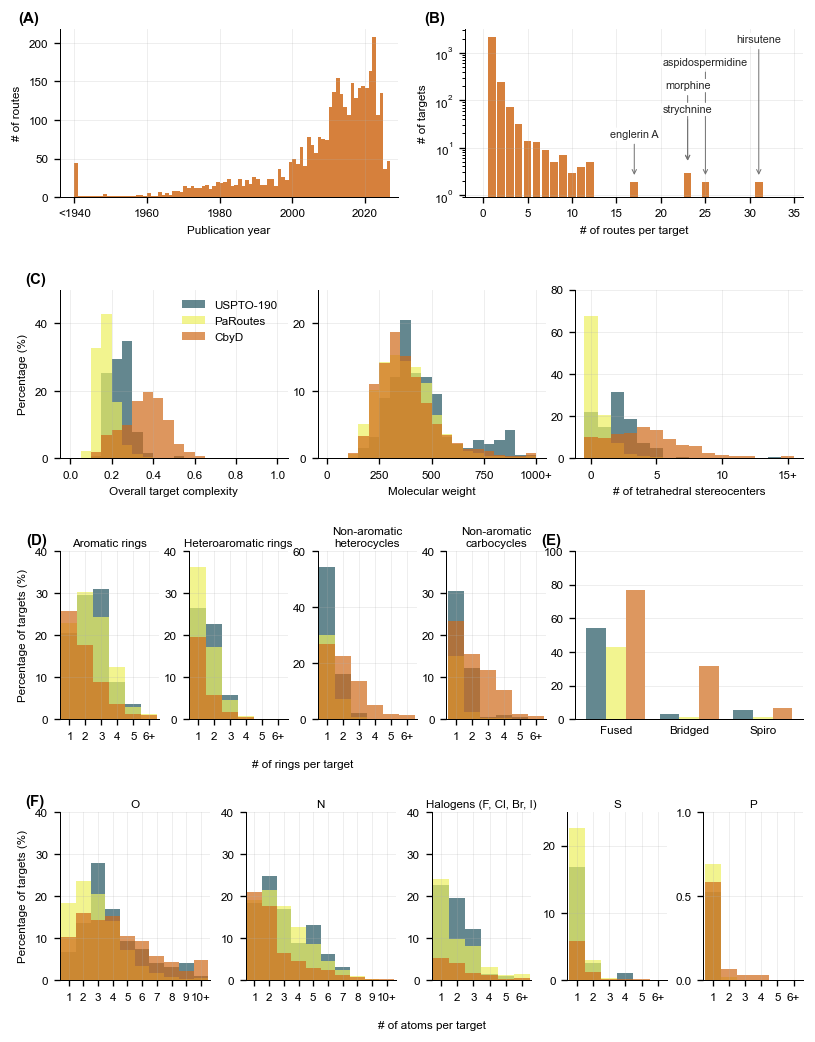

,n_routes,name
tkey,,
hirsutene,31,Hirsutene
aspidospermidine,25,Aspidospermidine
morphine,23,Morphine
strychnine,23,Strychnine
englerin a,17,Englerin A


In [4]:
years = ov.publication_years(topo)
routes_counts, top5 = ov.routes_per_target(topo)  # targets grouped by stereo-stripped name
ov.plot_overview(years, routes_counts, top5, targets, comp)
top5

**SI `target_complexity_metrics`** — the four raw scores averaged into overall complexity.

saved -> data/data_analysis/figures/SI/target_complexity_metrics.pdf


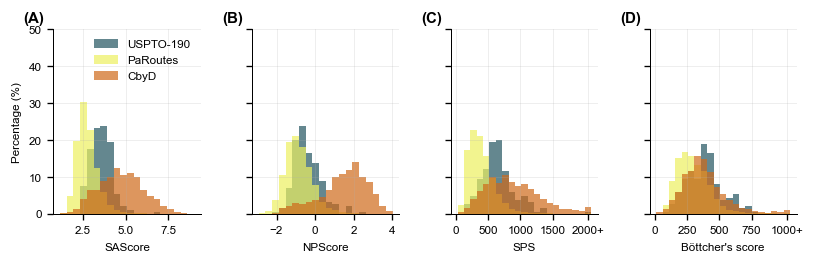

In [5]:
ov.plot_target_complexity_si(targets)

**SI `top15_heterocycles`** — most frequent ring systems with a ring N (A) or ring O (B) in CbyD targets. Fused / bridged rings are merged into one system, substituents stripped (exocyclic =X kept), stereo removed; each system counts once per target.

2,902 unique CbyD targets; 833 distinct N- and 819 distinct O-heterocyclic ring systems (0 failed)
saved -> data/data_analysis/figures/SI/top15_heterocycles.pdf


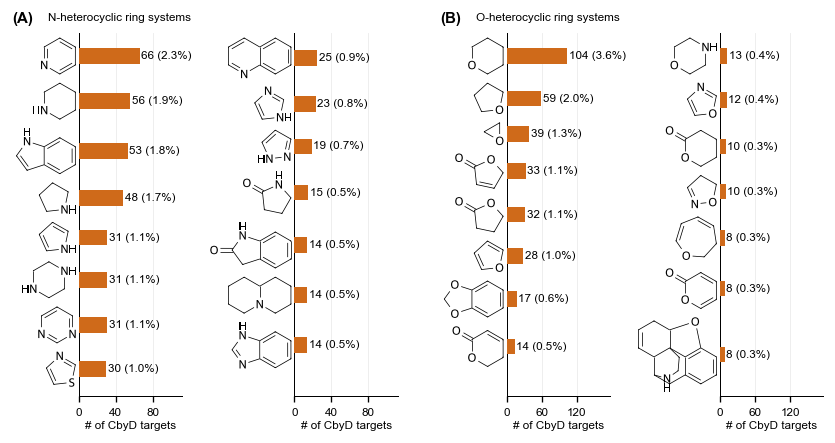

ring_system  n_targets  \
N-heterocyclic ring systems 0                            c1ccncc1         66   
                            1                            C1CCNCC1         56   
                            2                    c1ccc2[nH]ccc2c1         53   
                            3                             C1CCNC1         48   
                            4                          c1cc[nH]c1         31   
                            5                            C1CNCCN1         31   
                            6                            c1cncnc1         31   
                            7                             c1cscn1         30   
                            8                      c1ccc2ncccc2c1         25   
                            9                          c1c[nH]cn1         23   
                            10                         c1cn[nH]c1         19   
                            11                          O=C1CCCN1         15   
                            12                    O=C1Cc2ccccc2N1         14   
                            13                     C1CCN2CCCCC2C1         14   
                            14                   c1ccc2[nH]cnc2c1         14   
O-heterocyclic ring systems 0                            C1CCOCC1        104   
                            1                             C1CCOC1         59   
                            2                               C1CO1         39   
                            3                          O=C1C=CCO1         33   
                            4                           O=C1CCCO1         32   
                            5                             c1ccoc1         28   
                            6                     c1ccc2c(c1)OCO2         17   
                            7                         O=C1C=CCCO1         14   
                            8                            C1COCCN1         13   
                            9                             c1cocn1         12   
                            10                         O=C1CCCCO1         10   
                            11                           C1=NOCC1         10   
                            12                        C1=CCCOC=C1          8   
                            13                         O=c1cccco1          8   
                            14  C1=CC2C3Cc4cccc5c4C2(CCN3)C(C1)O5          8   

                                 pct  
N-heterocyclic ring systems 0   2.27  
                            1   1.93  
                            2   1.83  
                            3   1.65  
                            4   1.07  
                            5   1.07  
                            6   1.07  
                            7   1.03  
                            8   0.86  
                            9   0.79  
                            10  0.65  
                            11  0.52  
                            12  0.48  
                            13  0.48  
                            14  0.48  
O-heterocyclic ring systems 0   3.58  
                            1   2.03  
                            2   1.34  
                            3   1.14  
                            4   1.10  
                            5   0.96  
                            6   0.59  
                            7   0.48  
                            8   0.45  
                            9   0.41  
                            10  0.34  
                            11  0.34  
                            12  0.28  
                            13  0.28  
                            14  0.28

In [6]:
het, n_het = ov.heterocycle_counts(tc["CbyD"]["smiles"])
ov.plot_top_heterocycles([("(A)", "N-heterocyclic ring systems", het["N"]),
                          ("(B)", "O-heterocyclic ring systems", het["O"])], n_het, top=15)

## 2 · Reaction complexity

Unique CbyD reactions vs USPTO-Full and Pistachio.

In [7]:
feat, cls, uniq_ids = rc.load_reaction_tables()   # reaction features, NameRxn classes
fr, classes = rc.class_fractions(cls)              # fraction per first-level NameRxn class
metal = rc.load_metal_counts()                     # {dataset: {metal: count}}
overlap = rc.template_overlap("exact_match")       # CbyD reactions recovered by USPTO/Pistachio templates
{d: len(v) for d, v in feat.items()}

CbyD: 56,640 route steps -> 48,155 unique reactions


{'CbyD': 48155, 'USPTO-Full': 966744, 'Pistachio': 4326750}

**Figure `reaction_complexity`** — (A) NameRxn class distribution (0 = unrecognised); reacting atoms, changing rings, stereo changes (R/S + E/Z) · (B) area-proportional Venn of template recovery · (C) transition-metal rank-size (top 10).

saved -> data/data_analysis/figures/reaction_complexity.pdf


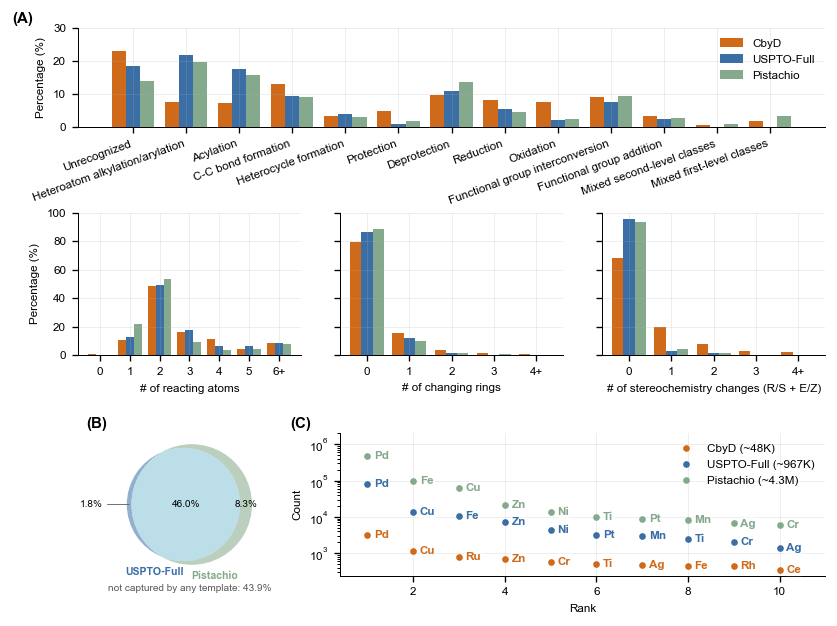

In [8]:
rc.plot_reaction_complexity(feat, fr, classes, metal, overlap)

**SI** — C–C / C–X bonds formed per reaction, and the complexity of each reaction's product (grey = all datasets pooled).

saved -> data/data_analysis/figures/SI/cc_cx_bonds.pdf


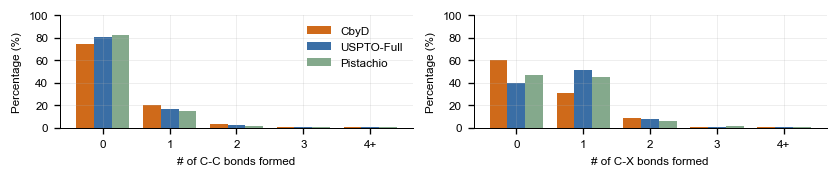

saved -> data/data_analysis/figures/SI/product_complexity.pdf


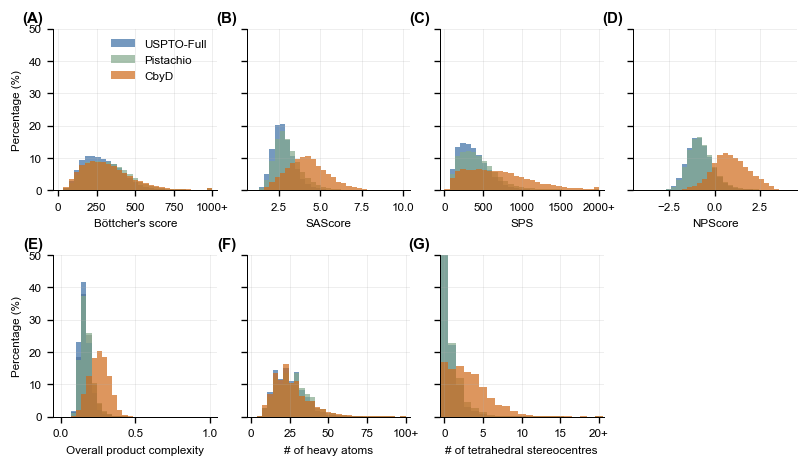

In [9]:
rc.plot_bonds_formed_si(feat)
rc.plot_product_complexity_si(rc.load_product_complexity(uniq_ids))

## 3 · Route analysis

CbyD vs PaRoutes and USPTO-190. A route is convergent when its total reactions exceed its longest linear sequence (LLS).

In [10]:
rtopo = ra.load_route_topology()
ra.route_length_summary(rtopo)

,routes,convergent,median # reactions,mean # reactions
USPTO-190,190.0,55.0,6.0,6.7
PaRoutes,10000.0,303.0,3.0,2.9
CbyD,3502.0,1351.0,14.0,16.2


**Figure `convergency_dot`** — total reactions vs LLS per route; insets: a convergent CbyD route and a linear one (arboduridine).

saved -> data/data_analysis/figures/convergency_dot.pdf


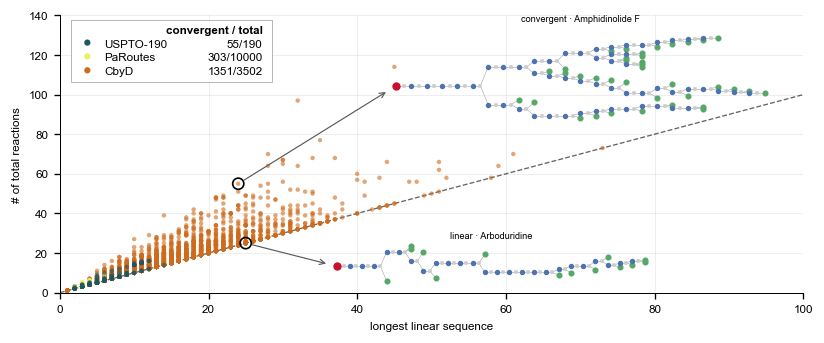

In [11]:
conv, lin = ra.example_routes(rtopo["CbyD"])
ra.plot_convergency(rtopo, conv, lin)

## 4 · Starting materials

Starting materials = un-produced reactants (role `start`). *Building blocks* = the chiral ones that are not reagent-like (no Si, B, sulfonyl, peroxide, N-halo, X–X).

CbyD: 995 building blocks of 6,919 un-produced reactants
USPTO-190: 38 building blocks
PaRoutes: 937 building blocks
CbyD: top 24 chiral building blocks


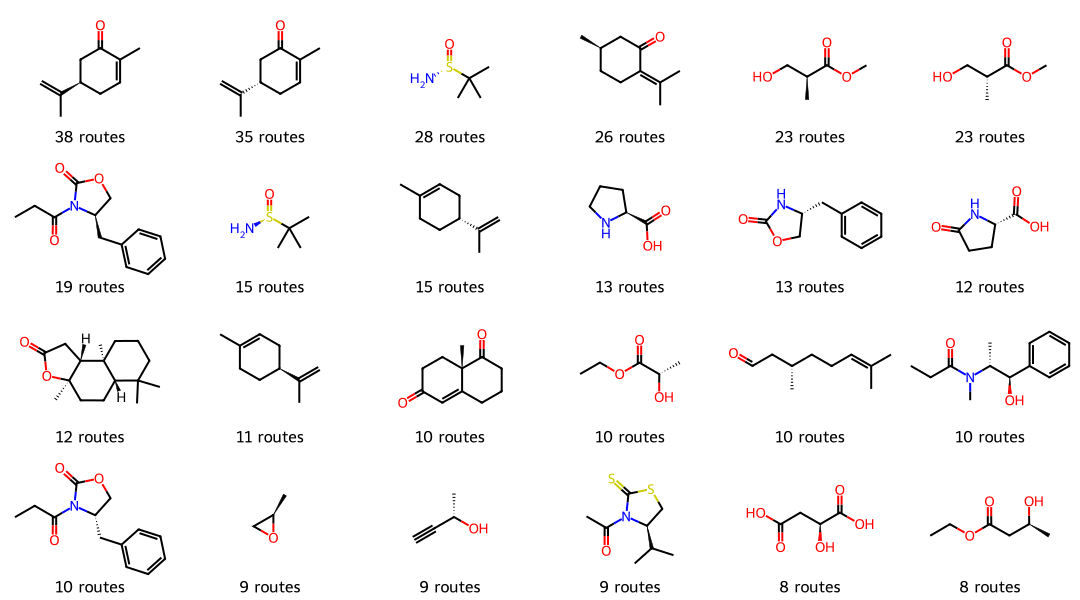

USPTO-190: top 24 chiral building blocks


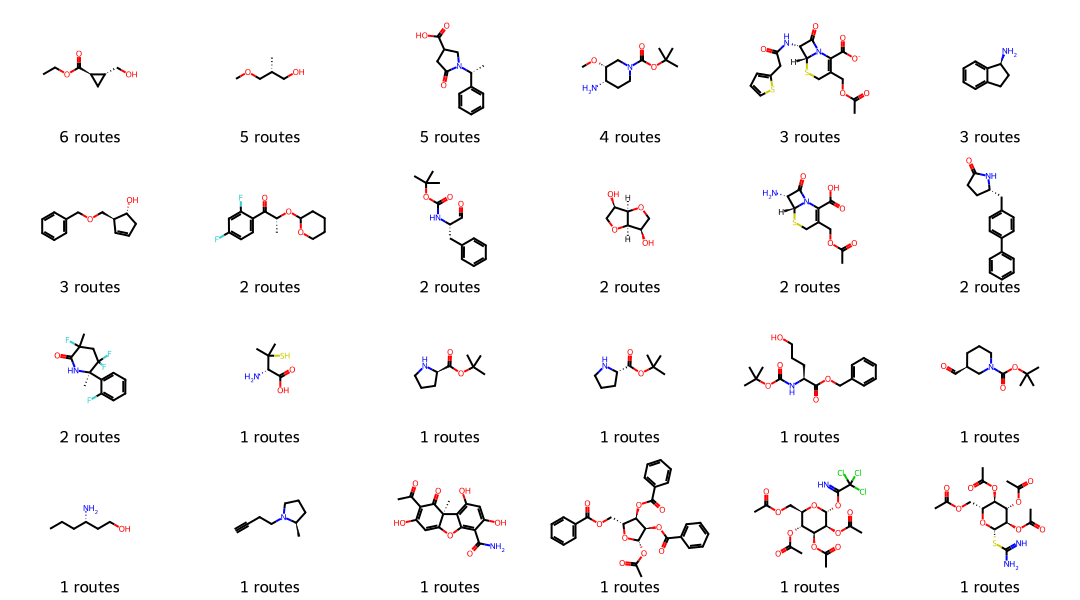

PaRoutes: top 24 chiral building blocks


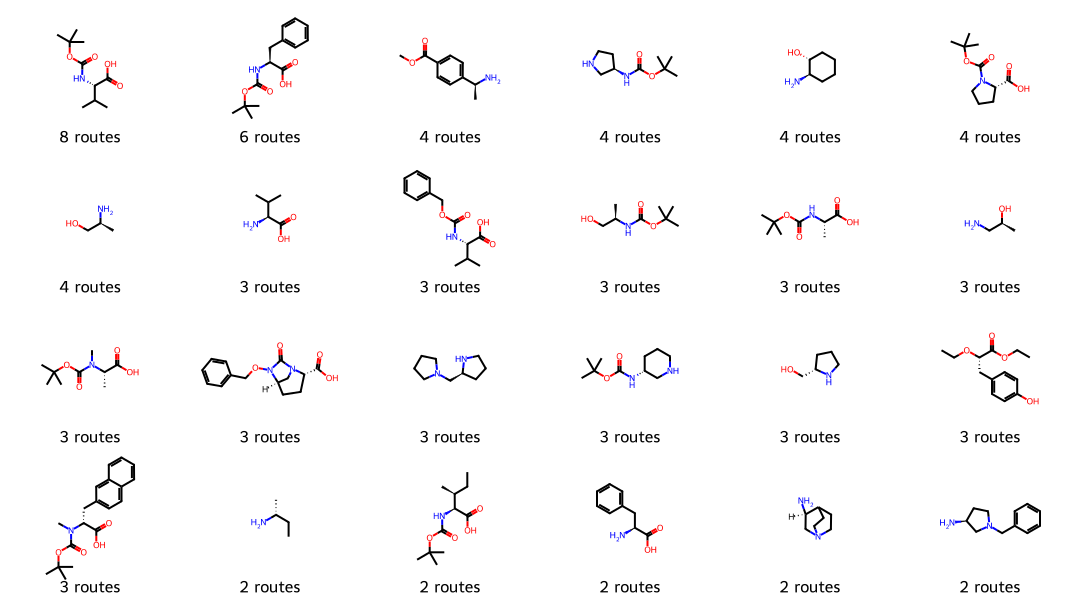

In [12]:
freq, freq_bb = sm.cbyd_starting_materials() 
u_bb = sm.uspto190_building_blocks()
p_bb = sm.paroutes_building_blocks()
for name, bb in [("CbyD", freq_bb), 
("USPTO-190", u_bb), 
("PaRoutes", p_bb)
]:
    print(f"{name}: top 24 chiral building blocks")
    display(sm.draw_top(bb, 24))

**Purchasability** — CbyD start molecules matched to the eMolecules catalogue (33.6 M) on RDKit canonical SMILES: *exact* stereoisomer, *flat* (any stereoisomer) and *normalised* (azide ↔ HN₃, covalent ↔ ionic organometallics, both ylide drawings, counterion-agnostic ions). Cached in `starting_materials/cbyd_sm_buyable.csv`.

loaded cached buyability -> starting_materials/cbyd_sm_buyable.csv


,n,%
,,
unique start molecules,6919.0,100.0
"buyable, exact stereoisomer",4491.0,64.9
"buyable, incl. normalised forms",4913.0,71.0
NOT buyable (after normalisation),2006.0,29.0
only a different stereoisomer sold,177.0,2.6
scaffold fully absent,2250.0,32.5
"NOT buyable, weighted by route count",NaN,32.3
of NOT buyable: carbon-containing,1923.0,95.9
"of NOT buyable: no carbon (H2O, I2, OsO4, ...)",83.0,4.1


   sections: carbon-containing: 25 in 3 rows; no carbon/inorganic: 25 in 2 rows; 7.50 x 3.21 in


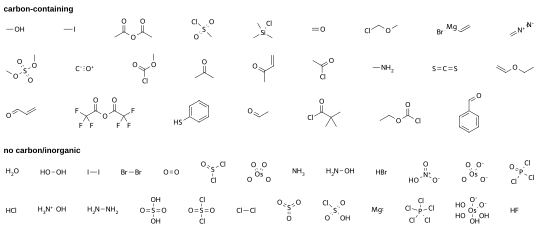

saved -> data/data_analysis/figures/SI/starting_materials_not_buyable.pdf


In [13]:
buy = sm.buyability(freq)
display(sm.buyability_summary(buy, freq_bb))
sm.plot_not_buyable(buy)                           # SI: most-used start molecules that are not buyable

**Target stereocentres: purchased or installed?** Each assigned stereocentre of a route's final target is traced back through the atom-mapped reactions: *purchased* = already set in a starting material, *installed* = created by a reaction, *unresolved* = mapping gap (`utils/stereo_provenance.py`; cached).

In [14]:
prov = sm.stereo_provenance()
display(sm.provenance_summary(prov).round(1))
sm.top_donors(prov)                                # chiral SMs donating a target stereocentre most often

loaded cached stereo provenance -> starting_materials/cbyd_stereo_provenance.csv
assigned stereocentres in final targets across 3,007 routes:


,stereocentres,% of all,% of resolved
installed (made by route),11345,82.8,82.8
purchased (from a chiral SM),2362,17.2,17.2
unresolved (mapping gap),0,0.0,NaN
total,13707,100.0,NaN


,purchased SM (SMILES),# routes
0,CC1(C)CCC[C@]2(C)[C@H]3CC(=O)O[C@]3(C)CC[C@@H]12,43
1,COC(=O)[C@@H](C)CO,38
2,C=C(C)[C@@H]1CC=C(C)C(=O)C1,31
3,C=C(C)[C@H]1CC=C(C)C(=O)C1,29
4,CC(C)=C1CC[C@@H](C)CC1=O,25
5,COC(=O)[C@H](C)CO,24
6,OC[C@H]1O[C@H](O)[C@H](O)[C@@H](O)[C@@H]1O,24
7,CC(C)[C@H](C)/C=C/[C@H](C)[C@@H]1CC[C@@H]2C3=C...,22
8,C=C/C(C)=C/C[C@H]1CCC[C@@H]2[C@]1(C)CCC[C@]2(C...,16
9,OC[C@H]1OC(O)[C@H](O)[C@@H](O)[C@@H]1O,16


Example route tree (SMs left → target right): stereocentres circled **red = installed**, **green = purchased**.

(+)-Preussin -> data/data_analysis/figures/SI/traced_stereo_provtree_preussin.svg


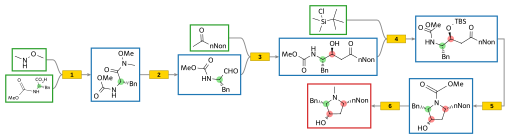

In [15]:
example = sm.provenance_example(prov)
out, svg = sm.provenance_tree_svg(example)
print(example["target"], "->", rel(out))
SVG(svg)

## 5 · Complexity evolution & key steps

Complexity of every in-tree CbyD reaction product along its route (synthetic progress 0 → 1 = 1 − (depth − 1)/LLS).

A **key step** has a complexity change Δ in the **top 10% of all candidate steps** (one threshold per score). Δ = C − (A + B) for the additive Böttcher and SPS, Δ = C − max(A, B) for the per-molecule SAScore and NPScore (C = product, A, B = reactants). Never key steps: (de)protection, redox (NameRxn classes 5–8), cyclic acetal / ketal / dithiane formation, and steps without a NameRxn class.

In [16]:
rxn, scored = ce.build_reaction_table()           # per-reaction depth, LLS, complexity, NameRxn
steps, thresh = ce.key_step_candidates(rxn, scored)
rs = ce.route_scores(rxn, scored, steps, thresh)  # lookups for the route-level plots
ce.keystep_summary(steps, thresh)

snapshot routes mapped to current route files: 3,502 of 3,502
56,423 in-tree reactions in 3,502 current routes; 56,417 matched to the snapshot, 6 new/edited (no NameRxn class)
reactant/new-product complexity cached -> complexity/cbyd_reactant_complexity.csv
38,872 candidate steps (of 56,423) after excluding (de)protection/redox, 334 cyclic acetal/ketal formations and unclassified new steps


,Δ threshold,key steps
score,,
Böttcher's score,34.415,3742
SAScore,0.658,3888
SPS,160.000,3961
NPScore,0.621,3888


**SI `complexity_evolution_keysteps`** — complexity vs progress (thin = 400 random routes, bold = mean per 5% bin) and the top-10 NameRxn key-step reactions per score (unrecognised and classes 11/12 removed; counts in `SI/top10_keysteps.csv`).

saved -> data/data_analysis/figures/SI/complexity_evolution_keysteps.pdf


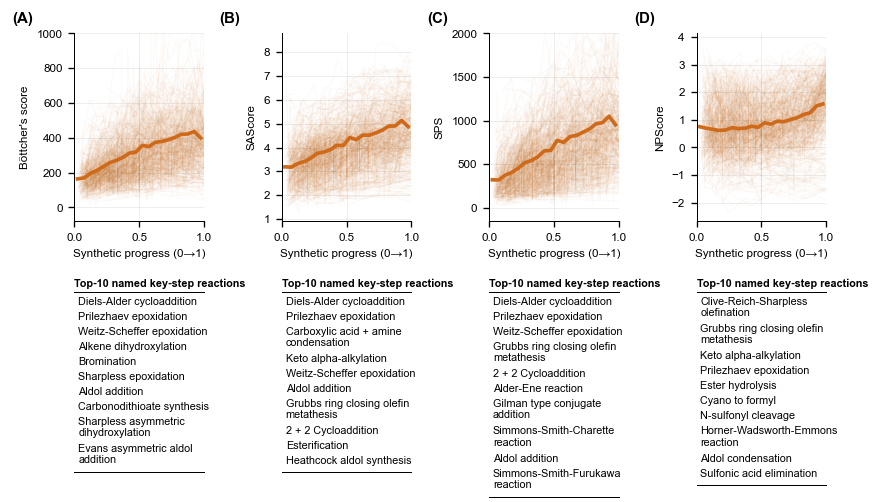

Böttcher's score (n=2,208)             \
                                          Reaction    N     %   
Rank                                                            
1                 3.11.3 Diels-Alder cycloaddition  225  10.2   
2                     4.2.8 Prilezhaev epoxidation  155   7.0   
3               4.2.148 Weitz-Scheffer epoxidation   98   4.4   
4                    10.4.9 Alkene dihydroxylation   61   2.8   
5                               10.1.1 Bromination   57   2.6   
6                     4.2.42 Sharpless epoxidation   54   2.4   
7                            3.11.1 Aldol addition   53   2.4   
8                2.6.17 Carbonodithioate synthesis   52   2.4   
9     10.4.12 Sharpless asymmetric dihydroxylation   46   2.1   
10        3.11.159 Evans asymmetric aldol addition   42   1.9   

                                  SAScore (n=1,943)             \
                                           Reaction    N     %   
Rank                                                             
1                  3.11.3 Diels-Alder cycloaddition  196  10.1   
2                      4.2.8 Prilezhaev epoxidation   91   4.7   
3        2.1.2 Carboxylic acid + amine condensation   78   4.0   
4                     3.11.91 Keto alpha-alkylation   56   2.9   
5                4.2.148 Weitz-Scheffer epoxidation   50   2.6   
6                             3.11.1 Aldol addition   49   2.5   
7     3.9.207 Grubbs ring closing olefin metathesis   41   2.1   
8                      3.11.166 2 + 2 Cycloaddition   37   1.9   
9                              2.6.2 Esterification   36   1.9   
10               3.11.317 Heathcock aldol synthesis   34   1.7   

                                      SPS (n=1,987)             \
                                           Reaction    N     %   
Rank                                                             
1                  3.11.3 Diels-Alder cycloaddition  268  13.5   
2                      4.2.8 Prilezhaev epoxidation  193   9.7   
3                4.2.148 Weitz-Scheffer epoxidation   86   4.3   
4     3.9.207 Grubbs ring closing olefin metathesis   70   3.5   
5                      3.11.166 2 + 2 Cycloaddition   57   2.9   
6                       3.11.134 Alder-Ene reaction   43   2.2   
7            3.9.258 Gilman type conjugate addition   40   2.0   
8           3.9.116 Simmons-Smith-Charette reaction   35   1.8   
9                             3.11.1 Aldol addition   34   1.7   
10          3.9.142 Simmons-Smith-Furukawa reaction   33   1.7   

                                  NPScore (n=1,977)           
                                           Reaction   N    %  
Rank                                                          
1         9.7.320 Clive-Reich-Sharpless olefination  61  3.1  
2     3.9.207 Grubbs ring closing olefin metathesis  56  2.8  
3                     3.11.91 Keto alpha-alkylation  46  2.3  
4                      4.2.8 Prilezhaev epoxidation  37  1.9  
5                           9.7.61 Ester hydrolysis  31  1.6  
6                           9.7.182 Cyano to formyl  30  1.5  
7                       9.7.614 N-sulfonyl cleavage  29  1.5  
8           3.11.5 Horner-Wadsworth-Emmons reaction  26  1.3  
9                         3.11.2 Aldol condensation  25  1.3  
10                9.7.332 Sulfonic acid elimination  24  1.2

In [17]:
si_tabs, top10 = ce.plot_evolution_keysteps_si(rxn, steps, thresh)
top10

**SI route trees** — selected routes with their SAScore along the LLS; red = SAScore key step.

Isocomene_1981_Wender: SAScore key step(s) [4] (tree box numbers); 7.05 x 3.00 in -> figures/SI/keystep_sascore_tree_isocomene_1981_wender.svg


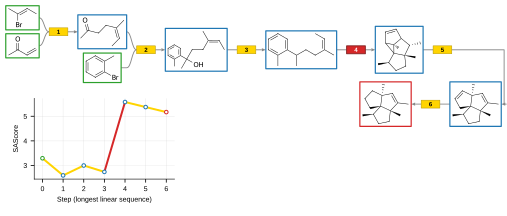

Kopsinine_2013_Boger: SAScore key step(s) [8, 14] (tree box numbers); 7.05 x 11.69 in -> figures/SI/keystep_sascore_tree_kopsinine_2013_boger.svg


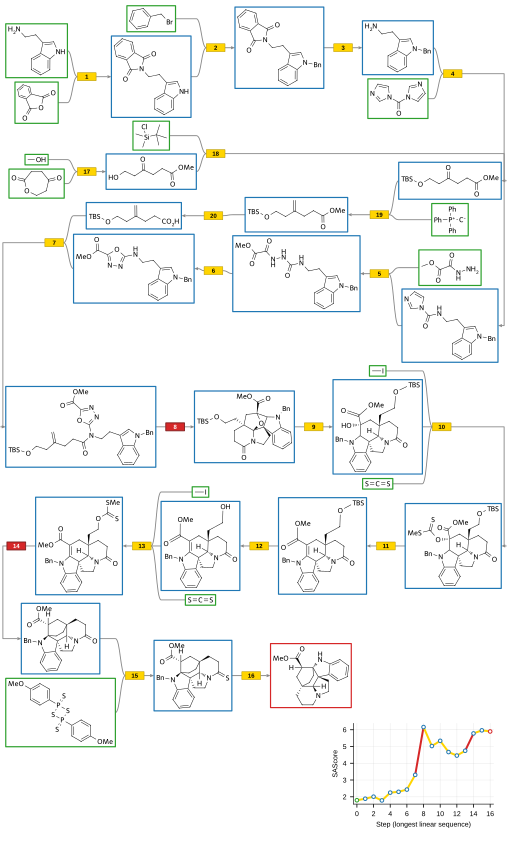

Isomatrine_2022_Reisman: SAScore key step(s) [1] (tree box numbers); 7.05 x 3.02 in -> figures/SI/keystep_sascore_tree_isomatrine_2022_reisman.svg


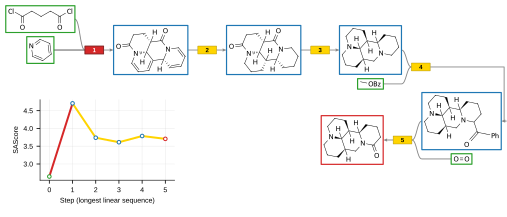

Penicibilaene_A_2021_Dong: SAScore key step(s) [5] (tree box numbers); 7.05 x 6.87 in -> figures/SI/keystep_sascore_tree_penicibilaene_a_2021_dong.svg


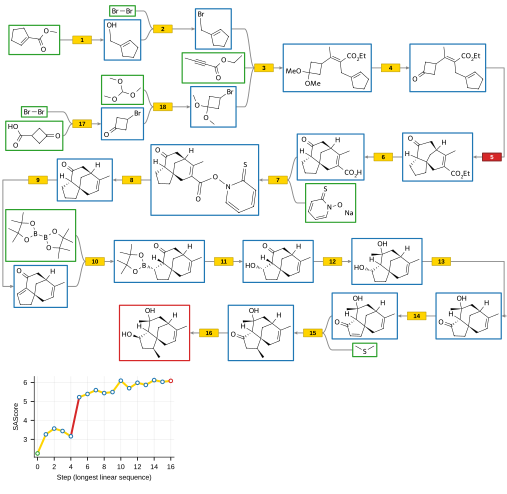

Longifolene_2022_Sarpong: SAScore key step(s) [2, 7] (tree box numbers); 7.05 x 4.55 in -> figures/SI/keystep_sascore_tree_longifolene_2022_sarpong.svg


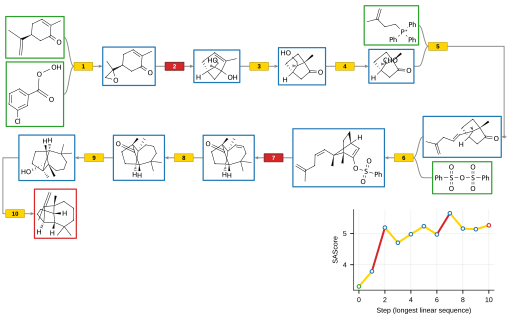

In [18]:
EXTRA_ROUTES = ["Isocomene_1981_Wender.json", "Kopsinine_2013_Boger.json",
                "Isomatrine_2022_Reisman.json", "Penicibilaene_A_2021_Dong.json",
                "Longifolene_2022_Sarpong.json"]
for route in EXTRA_ROUTES:
    _, svg = ce.save_keystep_figure_svg(route, rs)
    display(SVG(svg))

**Figure `sascore_keysteps`** — (A) SAScore vs progress for all routes · (B) example cards: SAScore along the LLS with the drawn step in red, target in a bubble, and the key step with its conditions. Edit `MAIN_EXAMPLES` to change a scheme (route, LLS position of the step, conditions) and `GRID_ROWS` to move cards.

all molecules at 0.1300-in bonds
   Kopsinine (Boger, 2013): step 8; scheme 3.20 in
   (+/-)-Isocomene (Wender, 1981): step 4; scheme 2.16 in
   Penicibilaene A (Dong, 2021): step 5; scheme 2.73 in
   (-)-Longifolene (Sarpong, 2022): step 2; scheme 1.73 in
   (+)-Isomatrine (Reisman, 2022): step 1; scheme 2.79 in
saved -> data/data_analysis/figures/sascore_keysteps.pdf  (7.00 x 8.74 in)


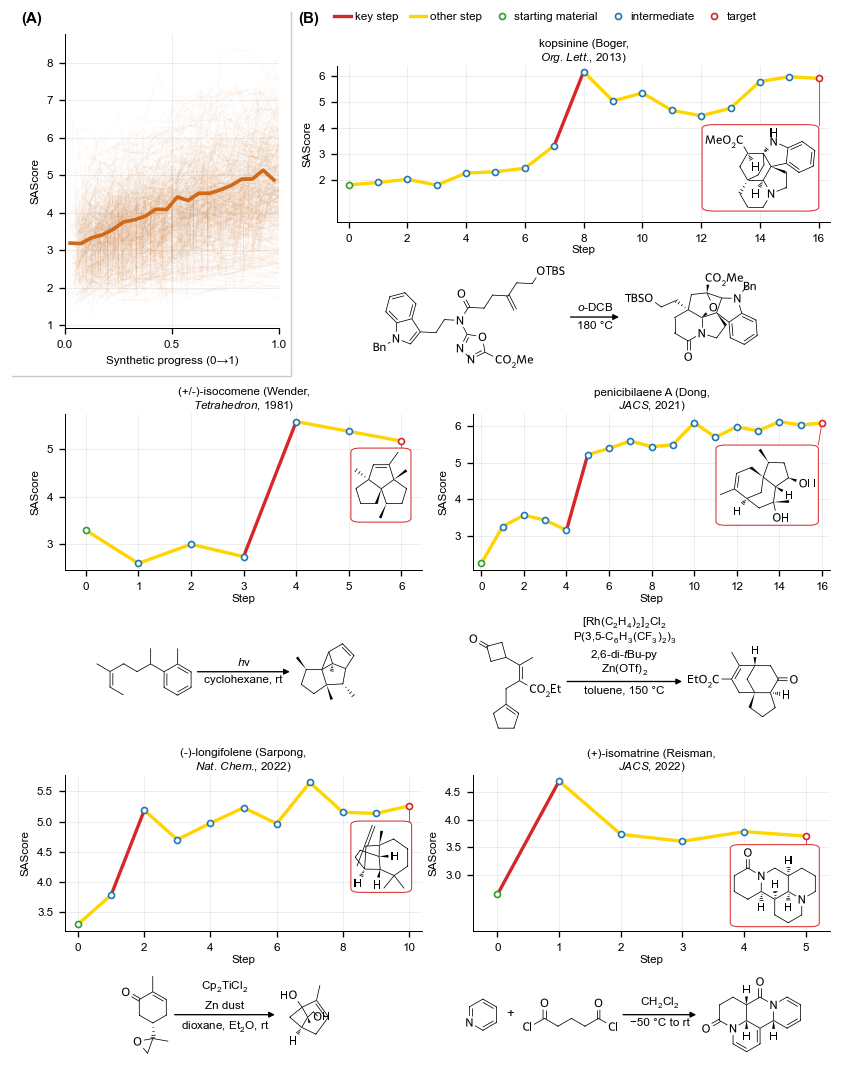

In [19]:
MAIN_EXAMPLES = [
    ("Isocomene_1981_Wender.json", 4,          # arene-alkene meta-photocycloaddition
     dict(above=[r"$\mathit{h}\nu$"], below=["cyclohexane, rt"])),
    ("Longifolene_2022_Sarpong.json", 2,       # Ti(III) epoxide opening / radical cyclization
     dict(above=["Cp$_2$TiCl$_2$", "Zn dust"], below=["dioxane, Et$_2$O, rt"])),
    ("Isomatrine_2022_Reisman.json", 1,        # dearomative annulation of pyridine
     dict(reactants=["c1ccncc1", "O=C(Cl)CCCC(=O)Cl"], above=["CH$_2$Cl$_2$"], below=["−50 °C to rt"])),
    ("Kopsinine_2013_Boger.json", 8,           # oxadiazole [4+2]/[3+2] cycloaddition cascade
     dict(above=[r"$\mathit{o}$-DCB"], below=["180 °C"])),
    ("Penicibilaene_A_2021_Dong.json", 5,      # Rh-catalysed cyclobutanone C–C activation ("cut-and-sew")
     dict(above=["[Rh(C$_2$H$_4$)$_2$]$_2$Cl$_2$", "P(3,5-C$_6$H$_3$(CF$_3$)$_2$)$_3$",
                 r"2,6-di-$\mathit{t}$Bu-py", "Zn(OTf)$_2$"], below=["toluene, 150 °C"])),
]
ISO, LONGI, ISOM, KOPS, PENI = (e[0] for e in MAIN_EXAMPLES)
GRID_ROWS = [[KOPS], [ISO, PENI], [LONGI, ISOM]]   # row 1 sits next to (A)
kf.grid_figure(GRID_ROWS, MAIN_EXAMPLES, rxn, rs, os.path.join(FIGURE_DIR, "sascore_keysteps.pdf"))

## 6 · Source data

The values plotted in each figure above, as tables, built from the same objects (`utils/source_data.py`).
Percentages are % of the dataset's molecules / reactions / routes, as in the figures; "k+" bins pool all values ≥ k.

In [20]:
book = sd.SourceData()                            # registry of every source-data table
s00 = sd.overview_tables(book, table1, topo, years, routes_counts, top5, targets, comp)   # § 1
s01 = sd.reaction_tables(book, feat, fr, classes, metal)                                  # § 2
s02 = sd.route_tables(book, rtopo)                                                        # § 3
sd.starting_material_tables(book, freq_bb, u_bb, p_bb, buy, prov)                         # § 4
sd.keystep_tables(book, rxn, steps, thresh, si_tabs, MAIN_EXAMPLES, rs)                   # § 5
book.index()

assigned stereocentres in final targets across 3,007 routes:


,table,figure,description,rows
0,table1_scope,Table 1,"Scope of CbyD: routes, reactions, unique targe...",5
1,routes_by_year,Dataset overview (A),Routes per publication year; 0 routes without ...,87
2,routes_per_target,Dataset overview (B),Number of targets with k routes (targets group...,16
3,top5_targets,Dataset overview (B),Five most frequently synthesised targets,5
4,target_property_summary,Dataset overview (C) / SI,Per-dataset summary of target properties (one ...,21
5,target_property_histograms,Dataset overview (C),Histograms as plotted (% of targets per bin),56
6,ring_types,Dataset overview (D),% of targets with k rings of each type,24
7,heteroatoms,Dataset overview (F),% of targets with k atoms of each element,38
8,ring_junctions,Dataset overview (E),% of targets with >=1 fused / bridged / spiro ...,3
9,composition_summary,Dataset overview (D–F),% of targets with at least one of each element...,11


**Table 2** (main-text candidate) — CbyD vs the comparison datasets across targets, routes and reactions. Medians with the interquartile range in parentheses; "—" = not applicable.

In [21]:
table2 = sd.table2(s00, s01, s02)
book.keep(table2, "table2_dataset_comparison", "Table 2 (main text)",
          "CbyD compared with USPTO-190, PaRoutes, USPTO-Full and Pistachio")
table2.set_index("")

,CbyD,USPTO-190,PaRoutes,USPTO-Full,Pistachio
,,,,,
Unique targets,"2,902",190,"10,000",—,—
Molecular weight,354 (288–449),418 (346–519),365 (282–455),—,—
Tetrahedral stereocentres,4 (2–6),2 (1–3),0 (0–1),—,—
Overall target complexity,0.37 (0.29–0.43),0.24 (0.20–0.27),0.17 (0.14–0.20),—,—
Targets with fused rings (%),76.7,54.2,43.2,—,—
Targets with bridged rings (%),31.8,3.2,1.5,—,—
Targets with spiro centres (%),6.7,5.3,1.6,—,—
Routes,"3,502",190,"10,000",—,—
Reactions per route,14 (9–21),6 (4–8),3 (2–3),—,—


**Supplementary tables** — the source-data tables as Table S1, S2, … in one editable Word file, `figures/SI/supplementary_tables.docx` (Times New Roman 12 pt, US Letter; table numbers are Word SEQ fields, select all + F9 renumbers). Per-item lists (top targets, individual routes, key-step reactions, example routes, building-block rankings, stereocentre donors) and Tables 1–2 are left out.

In [22]:
sd.write_docx(book, s00["n_year_excluded"], a("figures", "SI", "supplementary_tables.docx"))

17 tables (S1–S17) -> data/data_analysis/figures/SI/supplementary_tables.docx
